# Early-stop Adaptive Sampler: 95% HDI metrics and baseline comparison

This notebook intentionally writes *new* outputs under `results/early_stop/`; it never replaces `results/adaptivesampler_95ci_metrics.csv`.  It summarizes every `trace_*.nc` in `results/early_stop/adaptive_sampler/` and compares each parameter/configuration with the archived Adaptive Sampler baseline.

In [1]:
from pathlib import Path

repo_root = Path.cwd().resolve()
if not (repo_root / 'results').is_dir():
    repo_root = repo_root.parent
assert (repo_root / 'results').is_dir(), 'Start Jupyter from the repository root or results/'
outputs = repo_root / 'results' / 'early_stop'
outputs

PosixPath('/Users/preto/Documents/EPFL/PhD/transp-or/TooManyAlternativesToHandle/results/early_stop')

In [2]:
# Uses the same 95% HDI definitions as recreate_metrics_95ci.ipynb.
import os

exit_code = os.system(f'cd {repo_root} && conda run -n adasampler python results/summarize_early_stop_adaptive.py')
assert exit_code == 0, 'The summary script failed; check that the adasampler Conda environment exists.'

Wrote 90 rows to /Users/preto/Documents/EPFL/PhD/transp-or/TooManyAlternativesToHandle/results/early_stop/adaptivesampler_earlystop_95ci_metrics_261030.csv
Wrote 90 comparison rows to /Users/preto/Documents/EPFL/PhD/transp-or/TooManyAlternativesToHandle/results/early_stop/adaptivesampler_earlystop_vs_baseline_261030.csv
Wrote 10 summary rows to /Users/preto/Documents/EPFL/PhD/transp-or/TooManyAlternativesToHandle/results/early_stop/adaptivesampler_earlystop_vs_baseline_summary_261030.csv
   mean_abs_error_early_stop  mean_abs_error_baseline  rmse_early_stop  rmse_baseline  mean_interval_width_early_stop  mean_interval_width_baseline  coverage_early_stop  coverage_baseline  max_r_hat_early_stop  max_r_hat_baseline  mean_ess_bulk_early_stop  mean_ess_bulk_baseline    J      N    P
0                   0.026956                 0.031667         0.035598       0.045469                        0.550056                      0.364167                  1.0                1.0                  1.63 

In [3]:
import pandas as pd

summary_path = outputs / 'adaptivesampler_earlystop_vs_baseline_summary_261030.csv'
comparison_path = outputs / 'adaptivesampler_earlystop_vs_baseline_261030.csv'
display(pd.read_csv(summary_path))
display(pd.read_csv(comparison_path).head())

,mean_abs_error_early_stop,mean_abs_error_baseline,rmse_early_stop,rmse_baseline,mean_interval_width_early_stop,mean_interval_width_baseline,coverage_early_stop,coverage_baseline,max_r_hat_early_stop,max_r_hat_baseline,mean_ess_bulk_early_stop,mean_ess_bulk_baseline,J,N,P
0,0.026956,0.031667,0.035598,0.045469,0.550056,0.364167,1.0,1.0,1.63,1.11,128.711111,509.0,all,all,all
1,0.034200,0.035700,0.045040,0.050601,0.589400,0.449000,1.0,1.0,1.18,1.03,122.700000,535.7,100,10000,10
2,0.029500,0.015500,0.037774,0.021441,0.448700,0.324200,1.0,1.0,1.22,1.03,92.400000,475.0,100,20000,10
3,0.036100,0.015100,0.043613,0.020878,0.408500,0.303500,1.0,1.0,1.16,1.04,87.800000,298.5,100,50000,10
4,0.022800,0.044300,0.031981,0.053605,0.543600,0.431600,1.0,1.0,1.14,1.05,239.900000,635.9,200,10000,10
5,0.035600,0.071600,0.044326,0.085108,0.585100,0.391200,1.0,1.0,1.18,1.04,152.000000,593.9,200,20000,10
6,0.030500,0.048000,0.038508,0.058301,0.538400,0.308000,1.0,1.0,1.63,1.06,48.300000,445.3,200,50000,10
7,0.024400,0.023700,0.027214,0.026928,0.536500,0.390100,1.0,1.0,1.30,1.04,194.000000,706.5,500,10000,10
8,0.019400,0.020500,0.025132,0.027186,0.708600,0.327500,1.0,1.0,1.56,1.05,116.000000,565.1,500,20000,10
9,0.010100,0.010600,0.014300,0.013054,0.591700,0.352400,1.0,1.0,1.39,1.11,105.300000,325.1,500,50000,10


,J,N,P,parameter,estimator,posterior_mean_early_stop,posterior_sd,hdi_low,hdi_high,true_value,...,in_hdi_baseline,r_hat_baseline,ess_bulk_baseline,run_time_s_baseline,mean_difference,abs_error_change,sq_error_change,interval_width_change,interval_width_ratio,coverage_changed
0,100,10000,10,beta_rating,AdaptiveSamplerEarlyStop,0.747,0.056,0.668,0.845,0.75,...,True,1.00,1011.0,NaN,-0.005,1.000000e-03,0.000005,0.013,1.079268,False
1,100,10000,10,beta_cost,AdaptiveSamplerEarlyStop,-0.405,0.022,-0.423,-0.391,-0.40,...,True,1.00,1069.0,NaN,0.000,4.336809e-18,0.000000,0.001,1.032258,False
2,100,10000,10,beta_log_dist,AdaptiveSamplerEarlyStop,-0.586,0.043,-0.643,-0.526,-0.60,...,True,1.00,2554.0,NaN,-0.003,-3.000000e-03,-0.000093,-0.002,0.983193,False
3,100,10000,10,beta_chinese,AdaptiveSamplerEarlyStop,0.813,0.219,0.257,1.102,0.83,...,True,1.02,93.0,NaN,-0.047,-1.300000e-02,-0.000611,0.271,1.472125,False
4,100,10000,10,beta_japanese,AdaptiveSamplerEarlyStop,1.274,0.211,0.841,1.601,1.25,...,True,1.03,90.0,NaN,-0.047,-4.700000e-02,-0.004465,0.177,1.303602,False


## Per-trace convergence diagnostics

Set `parameter_display` to a coefficient suffix such as `"cost"`, `"rating"`, or `"chinese"`. The table reports the rank-normalized split R-hat and bulk/tail effective sample sizes for that parameter in every early-stop trace.

In [4]:
parameter_display = 'cost'  # e.g. 'rating', 'log_dist', or 'chinese'
parameter = parameter_display if parameter_display.startswith('beta_') else f'beta_{parameter_display}'

import arviz as az
import re

# The controller excludes tuning draws. They are retained in these NetCDF files,
# so recompute diagnostics on the final post-tune prefix only.
diagnostic_rows = []
for trace_path in sorted((outputs / 'adaptive_sampler').glob('trace_*.nc')):
    idata = az.from_netcdf(trace_path)
    if parameter not in idata.posterior:
        continue
    stored = idata.posterior[parameter]
    retained = int(idata.attrs.get('criterion_draws_per_chain', stored.sizes['draw']))
    if retained <= 0 or retained > stored.sizes['draw']:
        raise ValueError(f'Cannot determine post-tune draws for {trace_path.name}')
    post_tune = stored.isel(draw=slice(-retained, None))
    config = {key: int(value) for key, value in re.findall(r'([JNP])(\d+)', trace_path.name)}
    diagnostic_rows.append({
        **config,
        'file': trace_path.name,
        'chains': post_tune.sizes['chain'],
        'stored_draws_per_chain': stored.sizes['draw'],
        'post_tune_draws_per_chain': retained,
        'tuning_draws_excluded': stored.sizes['draw'] - retained,
        'r_hat': float(az.rhat(post_tune, method='rank').to_array().item()),
        'ess_bulk': float(az.ess(post_tune, method='bulk').to_array().item()),
        'ess_tail': float(az.ess(post_tune, method='tail').to_array().item()),
        'controller_r_hat': float(idata.attrs.get('criterion_rhat', float('nan'))),
    })

diagnostics = pd.DataFrame(diagnostic_rows).sort_values(['J', 'N']).reset_index(drop=True)
if diagnostics.empty:
    raise ValueError(f'No early-stop diagnostics found for {parameter!r}')
display(diagnostics)

,J,N,P,file,posterior_draws_per_chain,posterior_total_draws,r_hat,ess_bulk,ess_tail
0,100,10000,10,trace_J100_N10000_P10_prot2_mtm_steps10000_SCA...,2200,8800,1.02,222.0,332.0
1,100,20000,10,trace_J100_N20000_P10_prot2_mtm_steps10000_SCA...,2100,8400,1.01,510.0,333.0
2,100,50000,10,trace_J100_N50000_P10_prot2_mtm_steps10000_SCA...,3000,12000,1.04,84.0,44.0
3,200,10000,10,trace_J200_N10000_P10_prot2_mtm_steps10000_SCA...,3100,12400,1.01,556.0,527.0
4,200,20000,10,trace_J200_N20000_P10_prot2_mtm_steps10000_SCA...,2300,9200,1.01,539.0,485.0
5,200,50000,10,trace_J200_N50000_P10_prot2_mtm_steps10000_SCA...,1600,6400,1.04,119.0,34.0
6,500,10000,10,trace_J500_N10000_P10_prot2_mtm_steps10000_SCA...,2500,10000,1.01,577.0,516.0
7,500,20000,10,trace_J500_N20000_P10_prot2_mtm_steps10000_SCA...,2200,8800,1.01,416.0,190.0
8,500,50000,10,trace_J500_N50000_P10_prot2_mtm_steps10000_SCA...,2900,11600,1.02,419.0,430.0


Recomputing rank R-hat for trace_J100_N10000_P10_prot2_mtm_steps10000_SCALEearlystop_timed_261030.nc: 4 chains × 2200 draws
Recomputing rank R-hat for trace_J100_N20000_P10_prot2_mtm_steps10000_SCALEearlystop_timed_261030.nc: 4 chains × 2100 draws
Recomputing rank R-hat for trace_J100_N50000_P10_prot2_mtm_steps10000_SCALEearlystop_timed_261030.nc: 4 chains × 3000 draws
Recomputing rank R-hat for trace_J200_N10000_P10_prot2_mtm_steps10000_SCALEearlystop_timed_261030.nc: 4 chains × 3100 draws
Recomputing rank R-hat for trace_J200_N20000_P10_prot2_mtm_steps10000_SCALEearlystop_timed_261030.nc: 4 chains × 2300 draws
Recomputing rank R-hat for trace_J200_N50000_P10_prot2_mtm_steps10000_SCALEearlystop_timed_261030.nc: 4 chains × 1600 draws
Recomputing rank R-hat for trace_J500_N10000_P10_prot2_mtm_steps10000_SCALEearlystop_timed_261030.nc: 4 chains × 2500 draws
Recomputing rank R-hat for trace_J500_N20000_P10_prot2_mtm_steps10000_SCALEearlystop_timed_261030.nc: 4 chains × 2200 draws
Recomput

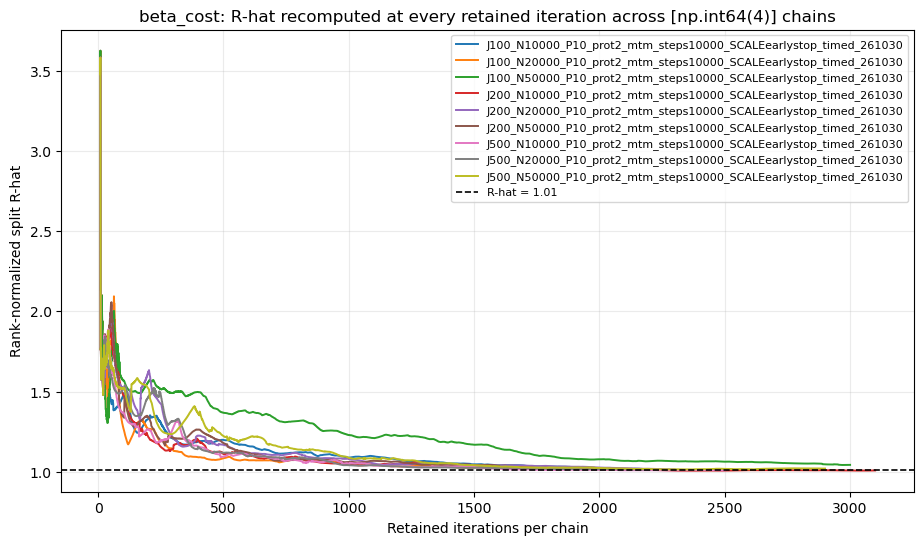

,trace,chains,iterations_per_chain,r_hat
0,trace_J100_N10000_P10_prot2_mtm_steps10000_SCA...,4,2200,1.016546
1,trace_J100_N20000_P10_prot2_mtm_steps10000_SCA...,4,2100,1.013293
2,trace_J100_N50000_P10_prot2_mtm_steps10000_SCA...,4,3000,1.042716
3,trace_J200_N10000_P10_prot2_mtm_steps10000_SCA...,4,3100,1.007874
4,trace_J200_N20000_P10_prot2_mtm_steps10000_SCA...,4,2300,1.014125
5,trace_J200_N50000_P10_prot2_mtm_steps10000_SCA...,4,1600,1.036738
6,trace_J500_N10000_P10_prot2_mtm_steps10000_SCA...,4,2500,1.008940
7,trace_J500_N20000_P10_prot2_mtm_steps10000_SCA...,4,2200,1.013008
8,trace_J500_N50000_P10_prot2_mtm_steps10000_SCA...,4,2900,1.019742


In [5]:
# R-hat is rank-normalized and recomputed on every retained-draw prefix across chains.
# On the x-axis, 1,000 means 1,000 retained iterations *per chain*.
import arviz as az
import matplotlib.pyplot as plt

parameter_display = 'cost'
parameter = parameter_display if parameter_display.startswith('beta_') else f'beta_{parameter_display}'
trace_display = 'all'  # 'all' or a configuration fragment, e.g. 'J100_N10000'
check_every = 1        # 1 recomputes R-hat at every retained iteration
min_draws_per_chain = 8

trace_root = outputs / 'adaptive_sampler'
trace_paths = sorted(trace_root.glob('trace_*.nc'))
if trace_display != 'all':
    trace_paths = [path for path in trace_paths if trace_display in path.name]
if not trace_paths:
    raise FileNotFoundError(f'No trace matched {trace_display!r} in {trace_root}')

rhat_rows = []
for trace_path in trace_paths:
    idata = az.from_netcdf(trace_path)
    if parameter not in idata.posterior:
        raise KeyError(f'{parameter!r} is not present in {trace_path.name}')
    stored_draws = idata.posterior[parameter]
    n_draws = int(idata.attrs.get('criterion_draws_per_chain', stored_draws.sizes['draw']))
    if n_draws <= 0 or n_draws > stored_draws.sizes['draw']:
        raise ValueError(f'Cannot determine post-tune draws for {trace_path.name}')
    draws = stored_draws.isel(draw=slice(-n_draws, None))
    n_chains = draws.sizes['chain']
    print(f'Recomputing rank R-hat for {trace_path.name}: {n_chains} chains × {n_draws} post-tune draws')
    for retained_draws in range(min_draws_per_chain, n_draws + 1, check_every):
        prefix = draws.isel(draw=slice(0, retained_draws))
        rhat = float(az.rhat(prefix, method='rank').to_array().item())
        rhat_rows.append({
            'trace': trace_path.name,
            'chains': n_chains,
            'iterations_per_chain': retained_draws,
            'r_hat': rhat,
        })

rhat_trajectory = pd.DataFrame(rhat_rows)
fig, ax = plt.subplots(figsize=(11, 6))
for trace_name, curve in rhat_trajectory.groupby('trace', sort=True):
    label = trace_name.replace('trace_', '').replace('.nc', '')
    ax.plot(curve['iterations_per_chain'], curve['r_hat'], linewidth=1.4, label=label)
ax.axhline(1.01, color='black', linestyle='--', linewidth=1.2, label='R-hat = 1.01')
ax.set_xlabel('Retained iterations per chain')
ax.set_ylabel('Rank-normalized split R-hat')
chain_counts = sorted(rhat_trajectory['chains'].unique())
ax.set_title(f'{parameter}: R-hat recomputed at every retained iteration across {chain_counts} chains')
ax.grid(alpha=0.25)
ax.legend(loc='best', fontsize=8)
plt.show()

display(rhat_trajectory.groupby(['trace', 'chains'], as_index=False).tail(1).reset_index(drop=True))